Having extracted the model data fields, plot a temperature map at a depth that just makes it over the Greenland-Scotland ridge, and add markers where each the profiles are extracted for the T-S plot.

In [2]:
import pickle

# Load the saved late profile data
with open('/Users/jaimepalter/Library/CloudStorage/OneDrive-UniversityofRhodeIsland/New Ideas/AMOC Lunch Bunch/profiles_late_period_DenStr.pkl', 'rb') as f:
   profiles_late = pickle.load(f)

print("✓ Denmark Strait 1995-2014 profiles loaded from 'profiles_late_period.pkl'")

✓ Denmark Strait 1995-2014 profiles loaded from 'profiles_late_period.pkl'


In [4]:
# Load model output already extractedin Nordic_Seas_V3 using:
from pathlib import Path
save_path = Path('/Users/jaimepalter/OneDrive - University of Rhode Island/New Ideas/AMOC Lunch Bunch/dset_dict.pkl')

with open(save_path, 'rb') as f:
    dset_dict = pickle.load(f)

In [8]:
"""
Extract successful models from T-S output
"""

# List of models that were NOT skipped (extracted from your output)
successful_models = [
    'GFDL-ESM4',
    'EC-Earth3-AerChem',
    'CMCC-ESM2',
    'CESM2-WACCM',
    'MPI-ESM-1-2-HAM',
    'CESM2-FV2',
    'FGOALS-g3',
    'CIESM',
    'ACCESS-ESM1-5',
    'CESM2',
    'GISS-E2-1-G',
    'MRI-ESM2-0',
    'MPI-ESM1-2-LR',
    'GISS-E2-1-G-CC',
    'NorESM2-MM',
    'CESM2-WACCM-FV2',
    'TaiESM1',
    'ACCESS-CM2',
    'CMCC-CM2-HR4',
    'CMCC-CM2-SR5',
    'IPSL-CM5A2-INCA',
    'NorESM2-LM',
    'GFDL-CM4',
    'EC-Earth3-Veg-LR',
    'SAM0-UNICON',
    'MIROC6'
]

# Sort alphabetically
successful_models_sorted = sorted(successful_models)

print(f"Successfully plotted models ({len(successful_models_sorted)}):")
print("="*60)
for i, model in enumerate(successful_models_sorted, 1):
    print(f"{i:2d}. {model}")

# Save to a file for reference
with open('successful_models_list.txt', 'w') as f:
    f.write(f"Successfully plotted models ({len(successful_models_sorted)})\n")
    f.write("="*60 + "\n")
    for model in successful_models_sorted:
        f.write(f"  {model}\n")

print("\n✓ Saved to 'successful_models_list.txt'")

Successfully plotted models (26):
 1. ACCESS-CM2
 2. ACCESS-ESM1-5
 3. CESM2
 4. CESM2-FV2
 5. CESM2-WACCM
 6. CESM2-WACCM-FV2
 7. CIESM
 8. CMCC-CM2-HR4
 9. CMCC-CM2-SR5
10. CMCC-ESM2
11. EC-Earth3-AerChem
12. EC-Earth3-Veg-LR
13. FGOALS-g3
14. GFDL-CM4
15. GFDL-ESM4
16. GISS-E2-1-G
17. GISS-E2-1-G-CC
18. IPSL-CM5A2-INCA
19. MIROC6
20. MPI-ESM-1-2-HAM
21. MPI-ESM1-2-LR
22. MRI-ESM2-0
23. NorESM2-LM
24. NorESM2-MM
25. SAM0-UNICON
26. TaiESM1

✓ Saved to 'successful_models_list.txt'


Filtering to 27 successful models

✓ CESM2-WACCM-FV2: Valid (75648 non-NaN points)
✓ CAMS-CSM1-0: Valid (41699 non-NaN points)
✓ MPI-ESM1-2-LR: Valid (28555 non-NaN points)
❌ SKIPPED NorESM2-MM: No 'lev' coordinate
✓ TaiESM1: Valid (75648 non-NaN points)
❌ SKIPPED IPSL-CM5A2-INCA: All NaN at depth slice
✓ CESM2: Valid (75648 non-NaN points)
✓ GISS-E2-1-G: Valid (29688 non-NaN points)
✓ MRI-ESM2-0: Valid (78801 non-NaN points)
✓ CIESM: Valid (75648 non-NaN points)
✓ EC-Earth3-AerChem: Valid (55493 non-NaN points)
✓ FGOALS-g3: Valid (47305 non-NaN points)
✓ CESM2-WACCM: Valid (75648 non-NaN points)
✓ EC-Earth3-Veg-LR: Valid (55493 non-NaN points)
✓ CMCC-CM2-SR5: Valid (55170 non-NaN points)
✓ GISS-E2-1-G-CC: Valid (29688 non-NaN points)
✓ GFDL-CM4: Valid (783820 non-NaN points)
✓ MPI-ESM-1-2-HAM: Valid (28555 non-NaN points)
✓ CESM2-FV2: Valid (75648 non-NaN points)
✓ ACCESS-CM2: Valid (57288 non-NaN points)
✓ CMCC-ESM2: Valid (55170 non-NaN points)
✓ GFDL-ESM4: Valid (220133 non-NaN poi

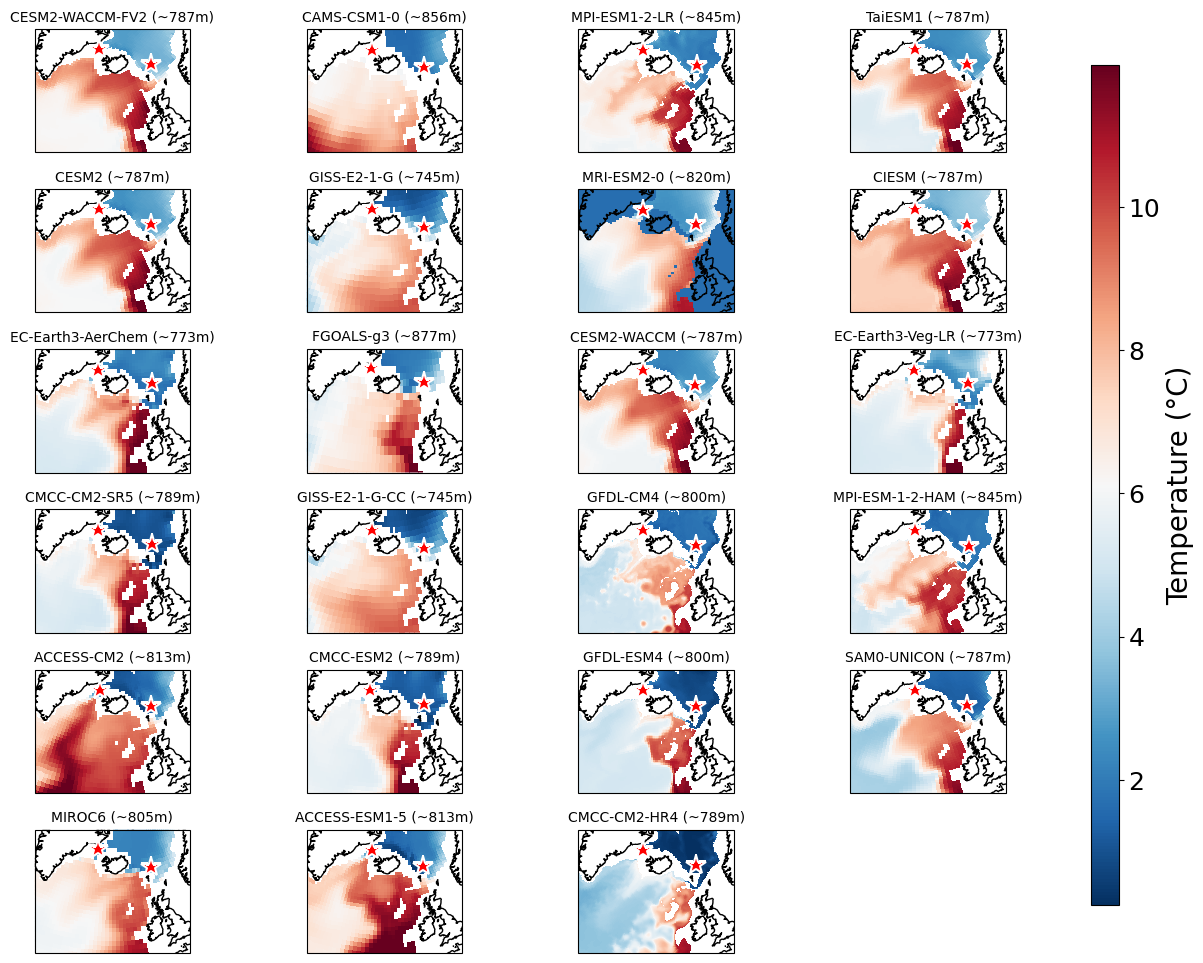

In [10]:
import matplotlib.pyplot as plt
import numpy as np
import cartopy.crs as ccrs
import time
from matplotlib.cm import ScalarMappable
import matplotlib.gridspec as gridspec



# ===== MODELS TO PLOT (only successful ones) =====
SUCCESSFUL_MODELS = {
    'ACCESS-CM2', 'ACCESS-ESM1-5', 'CAMS-CSM1-0', 'CESM2', 'CESM2-FV2',
    'CESM2-WACCM', 'CESM2-WACCM-FV2', 'CIESM', 'CMCC-CM2-HR4', 'CMCC-CM2-SR5',
    'CMCC-ESM2', 'EC-Earth3-AerChem', 'EC-Earth3-Veg-LR', 'FGOALS-g3', 'GFDL-CM4',
    'GFDL-ESM4', 'GISS-E2-1-G', 'GISS-E2-1-G-CC', 'IPSL-CM5A2-INCA', 'MIROC6',
    'MPI-ESM-1-2-HAM', 'MPI-ESM1-2-LR', 'MRI-ESM2-0', 'NorESM2-LM', 'NorESM2-MM',
    'SAM0-UNICON', 'TaiESM1'
}

# Set up subplots
models_to_plot = {k: v for k, v in dset_dict.items() 
                  if k.split(".")[2] in SUCCESSFUL_MODELS}

print(f"Filtering to {len(models_to_plot)} successful models\n")

# ===== VALIDATION PASS: Filter out bad models =====
valid_models = {}

for key, ds in models_to_plot.items():
    model_name = key.split(".")[2]
    
    # Check 1: Has required variable?
    if 'thetao' not in ds.data_vars or 'so' not in ds.data_vars:
        print(f"❌ SKIPPED {model_name}: Missing 'thetao' or 'so'")
        continue
    
    # Check 2: Has lev coordinate?
    if 'lev' not in ds.coords:
        print(f"❌ SKIPPED {model_name}: No 'lev' coordinate")
        continue
    
    # Check 3: Can we get a valid depth slice?
    try:
        depth_coord = ds['lev'].values
        target_depth = 800
        depth_idx = np.argmin(np.abs(depth_coord - target_depth))
        actual_depth = depth_coord[depth_idx]
        
        ds_period = ds.isel(time=-1)
        thetao = ds_period['thetao']
        temp_800m = thetao.isel(lev=depth_idx).squeeze()
        
        # Check 4: Does the depth slice have valid data?
        n_valid = (~np.isnan(temp_800m.values)).sum()
        if n_valid == 0:
            print(f"❌ SKIPPED {model_name}: All NaN at depth slice")
            continue
        
        # If we got here, this model is valid!
        valid_models[key] = ds
        print(f"✓ {model_name}: Valid ({n_valid} non-NaN points)")
        
    except Exception as e:
        print(f"❌ SKIPPED {model_name}: {type(e).__name__}: {e}")
        continue

print(f"\n{'='*60}")
print(f"Valid models: {len(valid_models)} / {len(models_to_plot)}")
print(f"{'='*60}\n")

# ===== FIRST PASS: Find global vmin/vmax across all models =====
print("Finding global temperature range...")
all_temps = []

for key, ds in valid_models.items():
    ds_period = ds.isel(time=-1)
    thetao = ds_period['thetao']
    depth_coord = ds['lev'].values
    target_depth = 800
    depth_idx = np.argmin(np.abs(depth_coord - target_depth))
    temp_800m = thetao.isel(lev=depth_idx).squeeze()
    all_temps.append(temp_800m.values[~np.isnan(temp_800m.values)])

all_temps = np.concatenate(all_temps)
vmin, vmax = np.nanpercentile(all_temps, [2, 98])  # Use 2nd and 98th percentiles to avoid extremes
print(f"Global temp range: {vmin:.2f} to {vmax:.2f} °C\n")

# ===== NOW CREATE SUBPLOTS ONLY FOR VALID MODELS =====
n_models = len(valid_models)
n_cols = 4
n_rows = (n_models + n_cols - 1) // n_cols

#fig = plt.figure(figsize=(16, n_rows * 5))
fig = plt.figure(figsize=(14, 12))
gs = gridspec.GridSpec(n_rows, n_cols, hspace=0.3, wspace=0.01)

print(f"Figure size: figsize=(16, {n_rows * 5})")
axes = []
for i in range(n_rows * n_cols):
    proj = ccrs.NorthPolarStereo(central_longitude=340)
    #ax = fig.add_subplot(n_rows, n_cols, i+1, projection=proj)
    ax = fig.add_subplot(gs[i], projection=proj)
    fig.subplots_adjust(hspace=0.2, wspace=0.2)  # Adjust these values
    axes.append(ax)
axes = np.array(axes)

# Define target locations
locations = {
    'DenStrait': {'lat': 67.5, 'lon': 334},
    #'FSChannel': {'lat': 67.5, 'lon': 357} #locations = {'FSChannel': {'lat': 67.5, 'lon': 357} }   # -4°W
    'FSChannel': {'lat': 64, 'lon': 356}
}

# Create colormap for all plots
cmap = plt.cm.RdBu_r
norm = plt.Normalize(vmin=vmin, vmax=vmax)

plot_idx = 0
for key, ds in valid_models.items():
    tic = time.perf_counter()
    model_name = key.split(".")[2]
    print(f"Processing {model_name}...")
    
    try:
        ds_period = ds.isel(time=-1)
        thetao = ds_period['thetao']
        
        # Get depth coordinate
        depth_coord = ds['lev'].values
        target_depth = 800
        depth_idx = np.argmin(np.abs(depth_coord - target_depth))
        actual_depth = depth_coord[depth_idx]
        
        # Select depth level
        temp_800m = thetao.isel(lev=depth_idx).squeeze()
        
        # Get lat/lon arrays
        lat_2d = ds['lat'].values
        lon_2d = ds['lon'].values
        
        # Ensure lat/lon shape matches data dimensions
        if lat_2d.shape != temp_800m.shape:
            lat_2d = lat_2d.T
            lon_2d = lon_2d.T
        
        # Use the Cartopy axis
        ax = axes[plot_idx]
        
        # Plot with shared norm (NO individual colorbar)
        im = ax.pcolormesh(lon_2d, lat_2d, temp_800m, 
                           cmap=cmap, norm=norm, shading='auto',
                           transform=ccrs.PlateCarree())
        ax.coastlines()
        
        # Add location markers
        for loc_name, coords in locations.items():
            lat_mask = np.abs(lat_2d - coords['lat']) <= 3
            lon_mask = np.abs(lon_2d - coords['lon']) <= 3
            search_region = lat_mask & lon_mask
            
            if np.any(search_region):
                lat_search = lat_2d[search_region]
                lon_search = lon_2d[search_region]
                dist_search = np.sqrt((lat_search - coords['lat'])**2 + 
                                     (lon_search - coords['lon'])**2)
                
                search_indices = np.where(search_region)
                nearest_idx = np.argmin(dist_search)
                row_id = search_indices[0][nearest_idx]
                col_id = search_indices[1][nearest_idx]
                
                nearest_lat = lat_2d[row_id, col_id]
                nearest_lon = lon_2d[row_id, col_id]
                
                ax.plot(nearest_lon, nearest_lat, 'r*', markersize=15, 
                       markeredgecolor='white', markeredgewidth=1.5, label=loc_name, 
                       transform=ccrs.PlateCarree(), zorder=1000)
        
        ax.set_title(f'{model_name} (~{round(actual_depth)}m)', fontsize=10)
        ax.set_extent([320, 360, 50, 70], crs=ccrs.PlateCarree())
        
        #if plot_idx == 0:
            #ax.legend(fontsize=10, loc='upper left')
        
        toc = time.perf_counter()
        print(f"  ✓ Successfully plotted in {toc - tic:.2f}s\n")
        
        plot_idx += 1
        
    except Exception as e:
        print(f"  ❌ ERROR during plotting: {type(e).__name__}: {e}\n")

# Hide unused subplots
for idx in range(plot_idx, len(axes)):
    axes[idx].axis('off')

# ===== ADD SINGLE COLORBAR =====
cbar_ax = fig.add_axes([0.92, 0.15, 0.02, 0.7])  # [left, bottom, width, height]
sm = ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
cbar = fig.colorbar(sm, cax=cbar_ax)

sm.set_array([])
cbar = fig.colorbar(sm, cax=cbar_ax)
cbar.ax.tick_params(labelsize=18)
fig.canvas.draw()


fig.canvas.draw()


cbar.set_label('Temperature (°C)', fontsize=20)

plt.subplots_adjust(right=0.9)  # Make room for colorbar

from pathlib import Path

save_path = Path('/Users/jaimepalter/OneDrive - University of Rhode Island/New Ideas/AMOC Lunch Bunch/Temperature_12_2014_800.png')
plt.savefig(save_path, dpi=300)#, bbox_inches='tight')
#plt.show()

In [30]:
from pathlib import Path

save_path = Path('/Users/jaimepalter/OneDrive - University of Rhode Island/New Ideas/AMOC Lunch Bunch/Temperature_12_2014_800.png')
fig.savefig(save_path, dpi=300, bbox_inches='tight')
